In [1]:
import pandas as pd
import numpy as np
import statistics as st
import scipy.stats as sc
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
ds = pd.read_csv("D:/Documents/Analysis and ML class/corporate_ai_adoption_dataset.csv")
ds.head()

,company_id,industry,country,year,ai_adoption_level,ai_investment_usd,automation_rate,cost_savings,revenue_impact,productivity_gain,employee_ai_training_hours,ai_maturity_score,deployment_count
0,CORP-06613,Financial Services,China,2029,0.4987,11747237,0.4119,3519354,2751513,0.3924,76.8,6.37,29
1,CORP-01597,Agriculture,Germany,2032,0.5213,1267219,0.4580,295244,304776,0.4639,83.2,7.19,37
2,CORP-02938,Energy,United States,2024,0.6147,8168951,0.5821,2472329,5170304,0.4953,123.1,6.72,26
3,CORP-05207,Retail,Germany,2021,0.4401,1234261,0.2880,512061,-233448,0.3078,63.1,5.68,21
4,CORP-07489,Technology,United States,2024,0.1918,5000645,0.1906,2122064,2110644,0.1910,29.6,4.33,16


In [3]:
ds_filtered = ds[ds['year'] <= 2023]

In [4]:
ds_filtered.head()

,company_id,industry,country,year,ai_adoption_level,ai_investment_usd,automation_rate,cost_savings,revenue_impact,productivity_gain,employee_ai_training_hours,ai_maturity_score,deployment_count
3,CORP-05207,Retail,Germany,2021,0.4401,1234261,0.2880,512061,-233448,0.3078,63.1,5.68,21
5,CORP-04524,Technology,China,2018,0.1588,2492956,0.1252,903015,556885,0.0916,33.3,3.25,10
6,CORP-06216,Manufacturing,Germany,2021,0.1917,1876245,0.1082,389831,-93417,0.0822,12.1,3.62,12
7,CORP-01925,Telecom,South Korea,2015,0.0846,1202819,0.0378,144186,218797,-0.0180,12.6,3.07,10
8,CORP-01012,Retail,United Kingdom,2022,0.3491,1636089,0.2861,441311,511607,0.2808,59.2,5.14,19


---Frequency Distribution---
industry
Technology            71593864024
Financial Services    69532176318
Manufacturing         36362785880
Healthcare            35150032661
Energy                23965828289
Telecom               21067591388
Logistics             15811412220
Retail                14904197871
Agriculture            3901434813
Education              2024871258
Name: ai_investment_usd, dtype: int64

---Country Investment---
country
United States     93524505440
China             54812961775
Germany           23288360226
United Kingdom    20700878549
Japan             18563322451
Canada            14582155242
France            13120865174
India             12763677899
South Korea       10434323391
Australia          7389293717
Singapore          6277138286
Brazil             6135406592
Sweden             5682472119
Netherlands        4948338237
UAE                2090495624
Name: ai_investment_usd, dtype: int64

---Investment Over Time---
year
2015    23543956383
2016    2

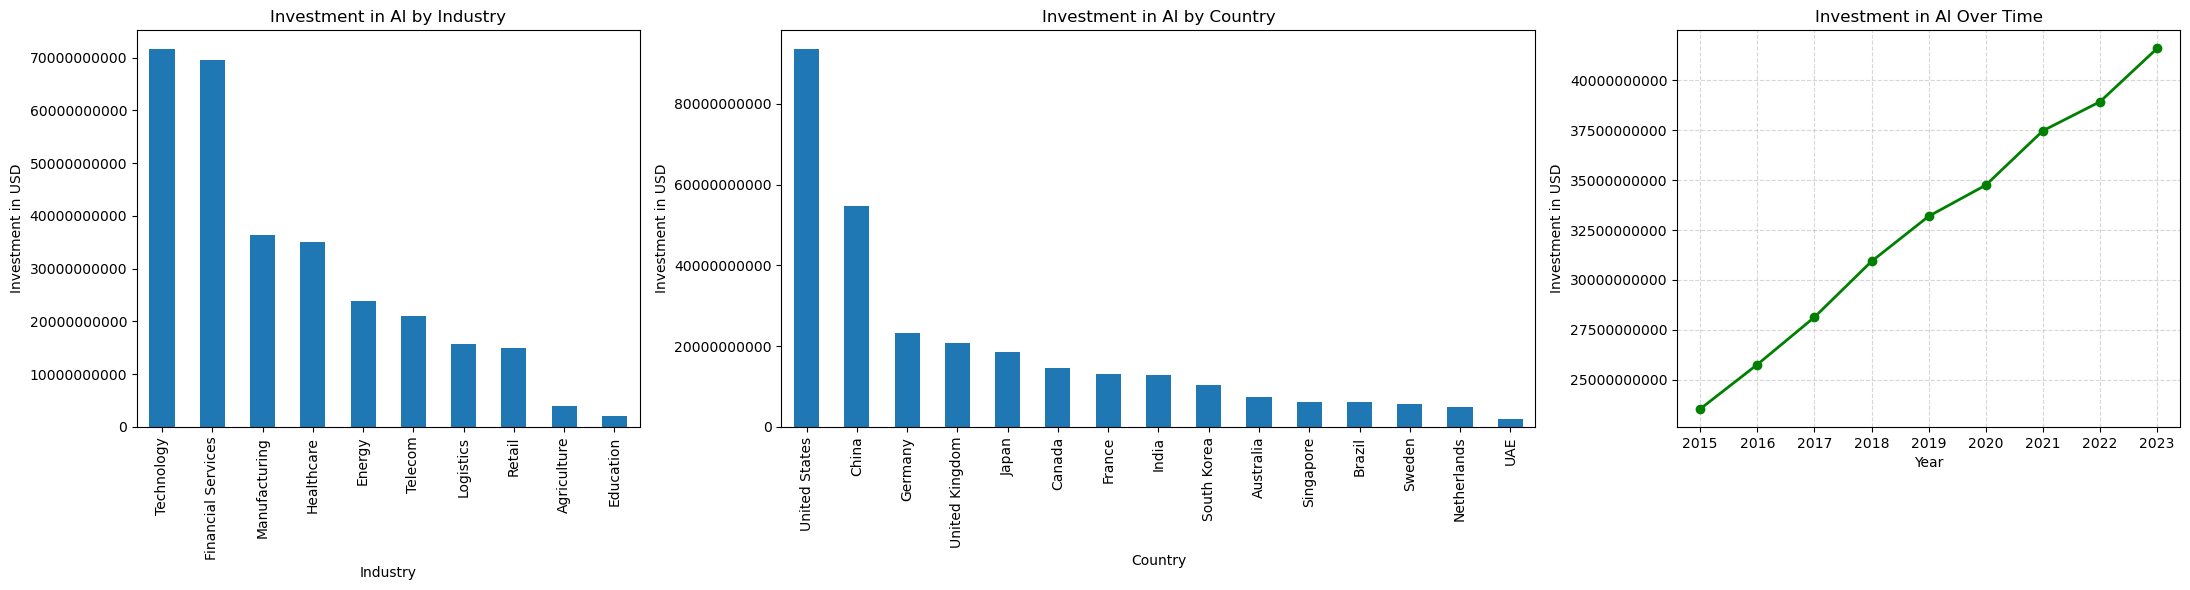

In [7]:
fig, axes = plt.subplots(
    1, 3, 
    figsize=(22, 6), 
    gridspec_kw={'width_ratios': [1, 1.5, 1]}
)

freq_dist = ds_filtered.groupby('industry')['ai_investment_usd'].sum().sort_values(ascending=False)
print("---Frequency Distribution---")
print(freq_dist)

freq_dist.plot(kind='bar', ax=axes[0])
axes[0].set_title("Investment in AI by Industry")
axes[0].set_xlabel('Industry')
axes[0].set_ylabel('Investment in USD')
axes[0].ticklabel_format(style='plain', axis='y')

axes[0].set_xticklabels(freq_dist.index, rotation=90, ha='center')

country_investment = ds_filtered.groupby('country')['ai_investment_usd'].sum().sort_values(ascending=False)
print("\n---Country Investment---")
print(country_investment)

country_investment.plot(kind='bar', ax=axes[1])
axes[1].set_title("Investment in AI by Country")
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Investment in USD')
axes[1].ticklabel_format(style='plain', axis='y')

axes[1].set_xticklabels(country_investment.index, rotation=90, ha='center')

time_investment = ds_filtered.groupby('year')['ai_investment_usd'].sum()
print("\n---Investment Over Time---")
print(time_investment)

time_investment.plot(kind='line', marker='o', color='green', linewidth=2, ax=axes[2])
axes[2].set_title("Investment in AI Over Time")
axes[2].set_xlabel('Year')
axes[2].set_ylabel('Investment in USD')
axes[2].ticklabel_format(style='plain', axis='y')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('InvestmentInAI.png')

---Yearly AI Adoption Level---
   year  ai_adoption_level
0  2015           0.191481
1  2016           0.220095
2  2017           0.252285
3  2018           0.287985
4  2019           0.320423
5  2020           0.353876
6  2021           0.390894
7  2022           0.426494
8  2023           0.455927

---Industry AI Adoption Level---
industry
Agriculture           0.325561
Financial Services    0.324687
Technology            0.322341
Retail                0.322192
Education             0.322035
Telecom               0.321615
Logistics             0.321248
Manufacturing         0.320816
Energy                0.320797
Healthcare            0.320350
Name: ai_adoption_level, dtype: float64

---Country AI Adoption Level---
country
United States     0.342789
Singapore         0.330913
United Kingdom    0.329318
Canada            0.321739
China             0.319467
Germany           0.318061
Sweden            0.316405
Japan             0.314069
France            0.313706
South Korea       0.31

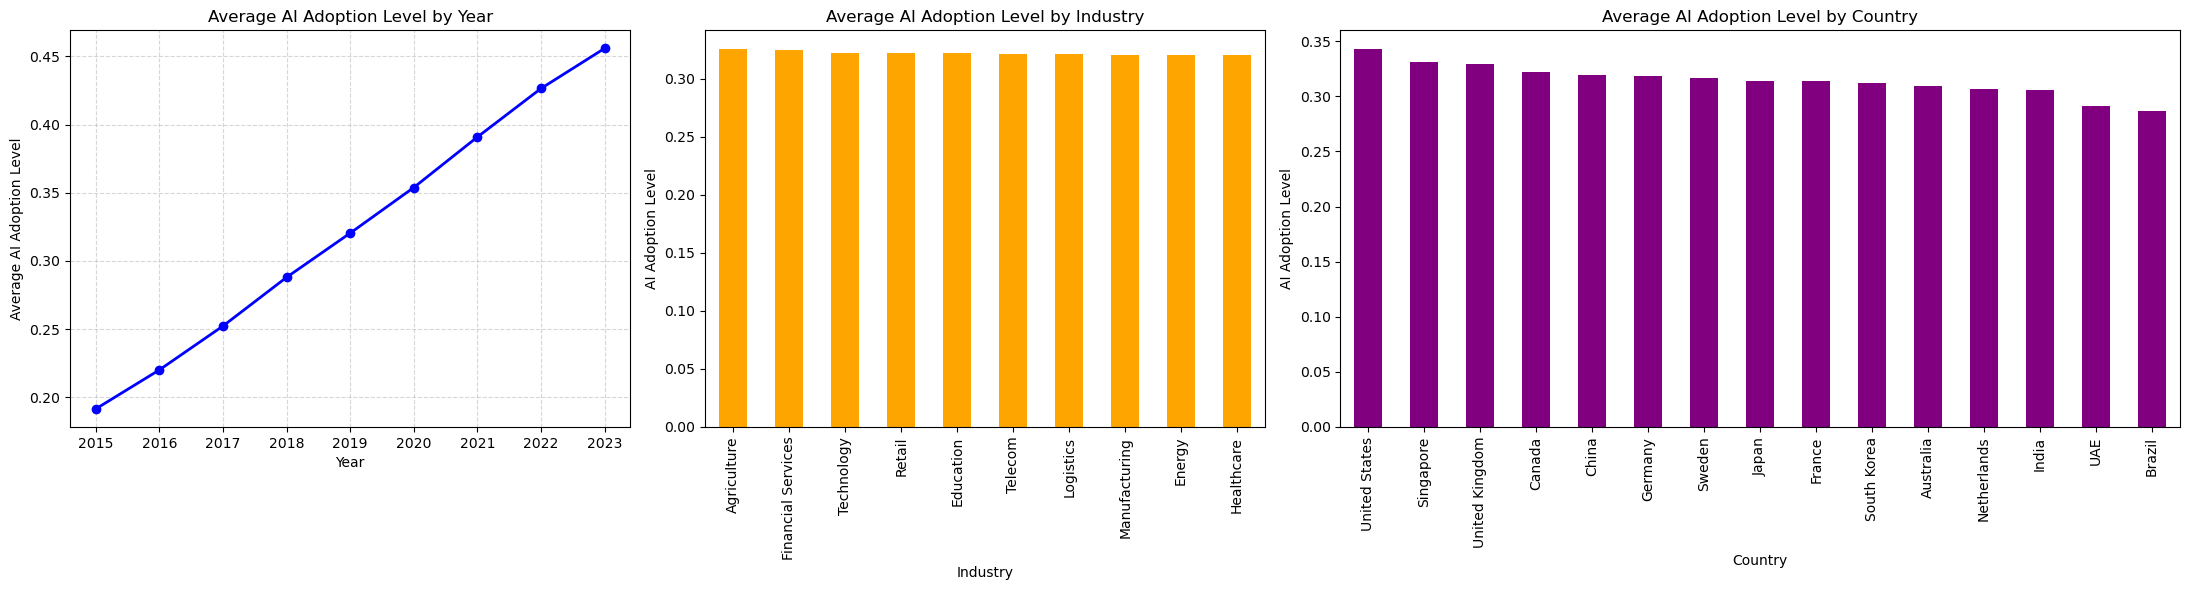

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 3, 
    figsize=(22, 6), 
    gridspec_kw={'width_ratios': [1, 1, 1.5]}  
)


yearly_trend = ds_filtered.groupby('year')['ai_adoption_level'].mean().reset_index()
print('---Yearly AI Adoption Level---')
print(yearly_trend)

axes[0].plot(yearly_trend['year'], yearly_trend['ai_adoption_level'], marker='o', linestyle='-', color='b', linewidth=2)
axes[0].set_title('Average AI Adoption Level by Year')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Average AI Adoption Level')
axes[0].grid(True, linestyle='--', alpha=0.5)

industry_ai = ds_filtered.groupby("industry")["ai_adoption_level"].mean().sort_values(ascending=False)
print("\n---Industry AI Adoption Level---")
print(industry_ai)

industry_ai.plot(kind="bar", ax=axes[1], color='orange')
axes[1].set_title("Average AI Adoption Level by Industry")
axes[1].set_xlabel('Industry')
axes[1].set_ylabel("AI Adoption Level")
axes[1].set_xticklabels(industry_ai.index, rotation=90, ha='center')

country_ai = ds_filtered.groupby("country")["ai_adoption_level"].mean().sort_values(ascending=False)
print("\n---Country AI Adoption Level---")
print(country_ai)

country_ai.plot(kind="bar", ax=axes[2], color='purple')
axes[2].set_title("Average AI Adoption Level by Country")
axes[2].set_xlabel('Country')
axes[2].set_ylabel("AI Adoption Level")
axes[2].set_xticklabels(country_ai.index, rotation=90, ha='center')

plt.tight_layout()
plt.savefig('AiAdoptionLevel.png')